In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())




/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


## per gene (compare method)

In [2]:
from scipy.stats import ks_2samp
import numpy as np

def ks_per_gene(x1, x2):
    # x1: torch tensor (cells × genes)
    # x2: AnnData

    # x1_np = x1.detach().cpu().numpy()
    x1_np = x1.X if isinstance(x1.X, np.ndarray) else x1.X.toarray()
    x2_np = x2.X if isinstance(x2.X, np.ndarray) else x2.X.toarray()

    ks_stats = []
    p_values = []
    # print("len",len(range(x1_np.shape[1])))
    for g in range(x1_np.shape[1]):  # loop over genes
        stat, p = ks_2samp(x1_np[:, g], x2_np[:, g])
        ks_stats.append(stat)
        p_values.append(p)

    return np.array(ks_stats), np.array(p_values)

real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450


/tmp/ipykernel_1339051/707349479.py:17: RuntimeWarning: divide by zero encountered in log10
  "neglog10_p_value": -np.log10(p_values)


real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450


/tmp/ipykernel_1339051/707349479.py:17: RuntimeWarning: divide by zero encountered in log10
  "neglog10_p_value": -np.log10(p_values)


real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450


/tmp/ipykernel_1339051/707349479.py:17: RuntimeWarning: divide by zero encountered in log10
  "neglog10_p_value": -np.log10(p_values)


real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450


/tmp/ipykernel_1339051/707349479.py:17: RuntimeWarning: divide by zero encountered in log10
  "neglog10_p_value": -np.log10(p_values)


real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450


/tmp/ipykernel_1339051/707349479.py:17: RuntimeWarning: divide by zero encountered in log10
  "neglog10_p_value": -np.log10(p_values)


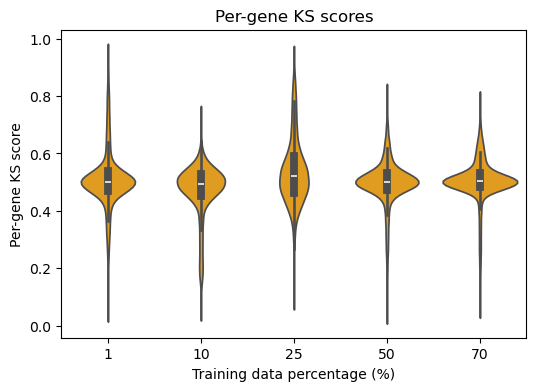

In [ ]:

df_all = []
for i in [1,10,25,50,70]:
    real_adata = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
    # real_adata = real_data_origin[real_data_origin.obs['Group']==3]
    # real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
    print("real_data:",real_adata)

    predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_{i}_percent/interception_predict_to_day_19.h5ad")
    print("predict_data:",predict_data)

    
    ks_stats, p_values = ks_per_gene(predict_data, real_adata)

    df_temp = pd.DataFrame({
        "Percentage": [str(i)] * len(ks_stats),
        "KS_stat": ks_stats,
        "neglog10_p_value": -np.log10(p_values)
    })

    df_all.append(df_temp)


# combine all percentages
df_all = pd.concat(df_all, ignore_index=True)

# violin plot
plt.figure(figsize=(6, 4), dpi=100)

sns.violinplot(
    x="Percentage",
    y="KS_stat",
    data=df_all,
    color="orange"
)

plt.xlabel("Training data percentage (%)")
plt.ylabel("Per-gene KS score")
plt.title("Per-gene KS scores")

plt.savefig(
    "ks_gene_score_violin.pdf",
    bbox_inches="tight"
)

plt.show()
    # plt.figure(figsize=(4, 2), dpi=100)
    # sns.boxplot(x='Sample', y='neglog10_p_value', data=df_ks_1, palette=['red', 'blue'])
    # plt.title(f"Per-gene KS statistics: neglog10_p_value, percentage {i}")
    # plt.savefig(f"ks_p_value_compare_percentage_{i}.pdf", bbox_inches="tight")
    # # plt.show()
    # plt.figure(figsize=(4, 2), dpi=100)
    # sns.boxplot(x='Sample', y='KS_stat', data=df_ks_1, palette=['red', 'blue'])
    # plt.title(f"Per-gene KS statistics: KS_stat, percentage {i}")
    # plt.savefig(f"ks_ks_stats_compare_percentage_{i}.pdf", bbox_inches="tight")


    # print("new method vs squidiff median:", np.median(ks_stats_1), np.median(ks_stats_2))
    # print("new method vs squidiff highest:", np.max(ks_stats_1), np.max(ks_stats_2))
    # print("new method vs squidiff lowest:", np.min(ks_stats_1), np.min(ks_stats_2))
    # print("new method vs squidiff range:", np.max(ks_stats_1) - np.min(ks_stats_1), np.max(ks_stats_2) - np.min(ks_stats_2))

## compare mainly by D, smaller D is better, larger P is better

In [4]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import ndtest
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import DistanceMetric

def get_pairwase_2d(x2, x3):
    x2_np = x2.X if isinstance(x2.X, np.ndarray) else x2.X.toarray()
    x3_np = x3.X if isinstance(x3.X, np.ndarray) else x3.X.toarray()
    
    print("new method vs real data cells number:", len(x2_np), len(x3_np))

    X_all = np.vstack([x2_np, x3_np])
    
    # track source
    index = np.array(['x2'] * len(x2_np) + ['x3'] * len(x3_np))

    pca = PCA(n_components=2)
    X_all_2d_before = pca.fit_transform(X_all)

    scaler = MinMaxScaler()
    X_all_2d = scaler.fit_transform(X_all_2d_before)

    # separate after PCA
    x2_2d = X_all_2d[index == 'x2']
    x3_2d = X_all_2d[index == 'x3']

    dist = DistanceMetric.get_metric('euclidean')
    D_n = dist.pairwise(x2_2d, x3_2d)

    # flatten to 1D
    all_distances_n = D_n.flatten()
    
    return all_distances_n


    # print("Mean:", mean_val)
    # print("Variance:", var_val)

def get_pca_2d(x2, x3, num):
    # x1_np = x1.detach().cpu().numpy()
    # x2_np = x2.detach().cpu().numpy()
    # x1_np = x1.X if isinstance(x1.X, np.ndarray) else x1.X.toarray()
    x2_np = x2.X if isinstance(x2.X, np.ndarray) else x2.X.toarray()
    x3_np = x3.X if isinstance(x3.X, np.ndarray) else x3.X.toarray()
    
    print(" new method vs real data cells number:", len(x2_np), len(x3_np))

    X_all = np.vstack([x2_np, x3_np])
    
    # Create index array to track source
    index = np.array(['x2'] * len(x2_np) + ['x3'] * len(x3_np))

    pca = PCA(n_components=2)
    X_all_2d_before = pca.fit_transform(X_all)

    scaler = MinMaxScaler()
    X_all_2d = scaler.fit_transform(X_all_2d_before)   # scaled to [0, 1]
    # Separate by index after PCA
    # x1_2d = X_all_2d[index == 'x1']#squidiff
    x2_2d = X_all_2d[index == 'x2']
    x3_2d = X_all_2d[index == 'x3']

    # x1_2d: generated cells, shape (n1, 2)
    # x2_2d: real cells, shape (n2, 2)
    # x1 = x1_2d[:, 0]  # PC1 of squidiff
    # y1 = x1_2d[:, 1]  # PC2 of squidiff

    x2 = x2_2d[:, 0]  # PC1 of new_method
    y2 = x2_2d[:, 1]  # PC2 of new_method

    x3 = x3_2d[:, 0]  # PC1 of real
    y3 = x3_2d[:, 1]  # PC1 of real
    # print("len",len(x1),len(y1),len(x2),len(y2),len(x3),len(y3))
    # P, D = ndtest.ks2d2s(x1, y1, x3, y3, extra=True)
    # print(f"squidiff method vs real data, gene num {num}: P={P:.3g}, D={D:.3g}")

    P, D = ndtest.ks2d2s(x2, y2, x3, y3, extra=True)
    print(f"new method vs real data, percentage {num}: P={P:.3g}, D={D:.3g}")

    # P, D = ndtest.ks2d2s(x1, y1, x2, y2, extra=True)
    # print(f"squidiff vs new method, gene num {num}: P={P:.3g}, D={D:.3g}")


    # # silhouette: 0 vs 2
    # X_s = np.vstack([x1_2d, x3_2d])
    # labels_s = np.array([0] * len(x1_2d) + [1] * len(x3_2d))
    # sil_s = silhouette_score(X_s, labels_s)
    # print(f"Silhouette squidiff vs real data, gene num {num}: {sil_s:.4f}")

    # silhouette: 1 vs 2
    X_n = np.vstack([x2_2d, x3_2d])
    labels_n = np.array([0] * len(x2_2d) + [1] * len(x3_2d))
    sil_n = silhouette_score(X_n, labels_n)
    print(f"Silhouette new method vs real data, percentage {num}: {sil_n:.4f}")

    # X_n = np.vstack([x1_2d, x2_2d])
    # labels_n = np.array([0] * len(x1_2d) + [1] * len(x2_2d))
    # sil_n = silhouette_score(X_n, labels_n)
    # print(f"Silhouette squidiff vs new method, gene num {num}: {sil_n:.4f}")

    plt.figure(figsize=(2, 2), dpi=300)

    # plt.scatter(x1, y1, s=2, alpha=1, c='blue', label='squidiff',edgecolors='none')
    plt.scatter(x2, y2, s=3, alpha=1, c='red', label='new method',edgecolors='none')
    plt.scatter(x3, y3, s=1, alpha=1, c='yellow', label='real data',edgecolors='none')


    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(f"PCA of cells\n2D KS")
    plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
    plt.tight_layout()
    plt.savefig(f"ks_pca_compare_percentage_{num}.pdf", bbox_inches="tight")
    # plt.show()

real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
new method vs real data cells number: 5592 5592
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
new method vs real data cells number: 5592 5592
predict_data: AnnData obje

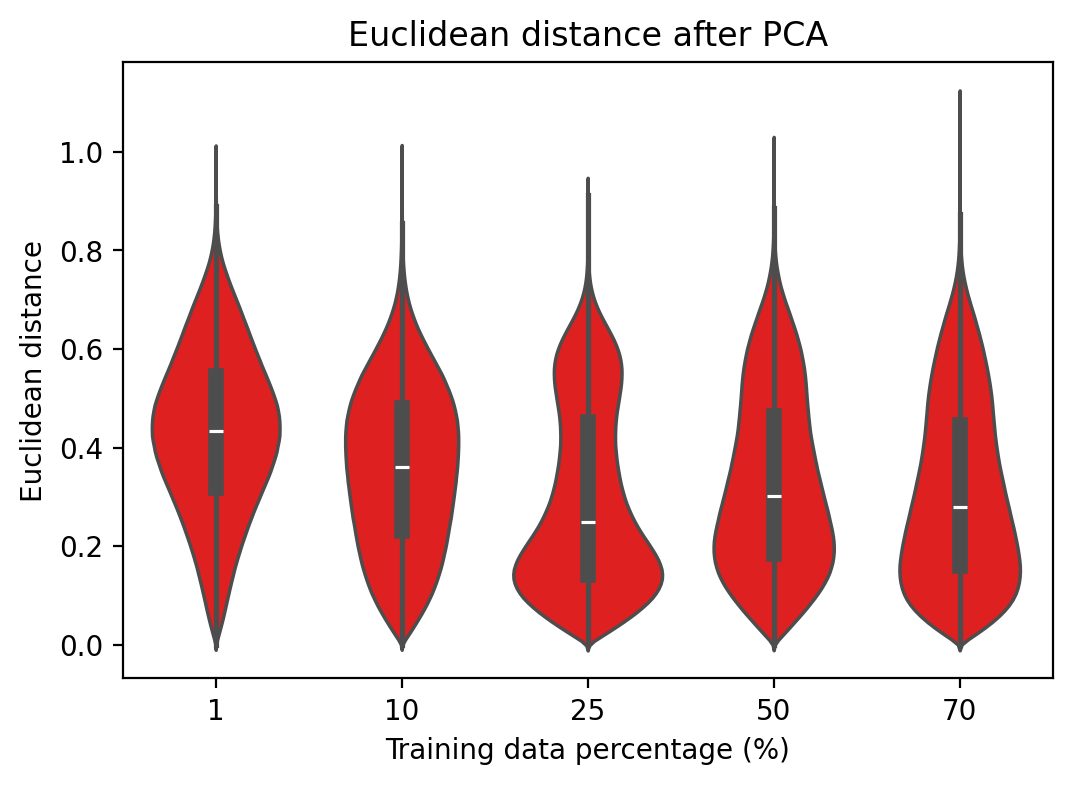

In [5]:
df_all = []

real_adata = sc.read_h5ad("../../input/test_data_day_19.h5ad")
print("real_data:", real_adata)

for i in [1, 10, 25, 50, 70]:
    predict_data = sc.read_h5ad(
        f"../experiments/mice_exp6_infer_day_except_19_by_7_18_{i}_percent/interception_predict_to_day_19.h5ad"
    )
    print("predict_data:", predict_data)

    distances = get_pairwase_2d(predict_data, real_adata)

    df_temp = pd.DataFrame({
        "Percentage": [str(i)] * len(distances),
        "distance": distances
    })

    df_all.append(df_temp)

df_all = pd.concat(df_all, ignore_index=True)
plt.figure(figsize=(6, 4), dpi=200)

sns.violinplot(
    x="Percentage",
    y="distance",
    data=df_all,
    color="red",   # change color here
    inner="box"
)

plt.xlabel("Training data percentage (%)")
plt.ylabel("Euclidean distance")
plt.title("Euclidean distance after PCA")
plt.savefig("Euclidean_distance_after_PCA_all_percentages.pdf", bbox_inches="tight")
plt.show()

real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
 new method vs real data cells number: 5592 5592
new method vs real data, percentage 1: P=0, D=0.89
Silhouette new method vs real data, percentage 1: 0.4000


/tmp/ipykernel_1339051/2938807224.py:115: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
 new method vs real data cells number: 5592 5592
new method vs real data, percentage 10: P=0, D=0.716
Silhouette new method vs real data, percentage 10: 0.2477


/tmp/ipykernel_1339051/2938807224.py:115: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
 new method vs real data cells number: 5592 5592
new method vs real data, percentage 25: P=0, D=0.653
Silhouette new method vs real data, percentage 25: 0.2237


/tmp/ipykernel_1339051/2938807224.py:115: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
 new method vs real data cells number: 5592 5592
new method vs real data, percentage 50: P=0, D=0.582
Silhouette new method vs real data, percentage 50: 0.1833


/tmp/ipykernel_1339051/2938807224.py:115: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


real_data: AnnData object with n_obs × n_vars = 5592 × 55450
    obs: 'CellID_Library', 'new_cellid_unique', 'doublet_score', 'embryonic_period', 'day', 'gender', 'mouse_part_summary', 'library_time', 'sample', 'n_counts', 'n_genes', 'percent_mito', 'predict_doublet', 'Gja5+_label', 'organ', 'label', 'Group'
    var: 'Ensembl_id'
    uns: 'Gja5+_label_colors', 'clusters_colors', 'clustes_colors', 'day_colors', 'embryonic_period_colors', 'hvg', 'label_2024_colors', 'label_colors', 'label_endoMT_colors', 'label_endo_colors', 'leiden', 'leiden_colors', 'mouse_part_summary_colors', 'neighbors', 'organ_colors', 'predict_label_colors', 'predict_proba', 'subtype_colors'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'
predict_data: AnnData object with n_obs × n_vars = 5592 × 55450
 new method vs real data cells number: 5592 5592
new method vs real data, percentage 70: P=0, D=0.494
Silhouette new method vs real data, percentage 70: 0.1272


/tmp/ipykernel_1339051/2938807224.py:115: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


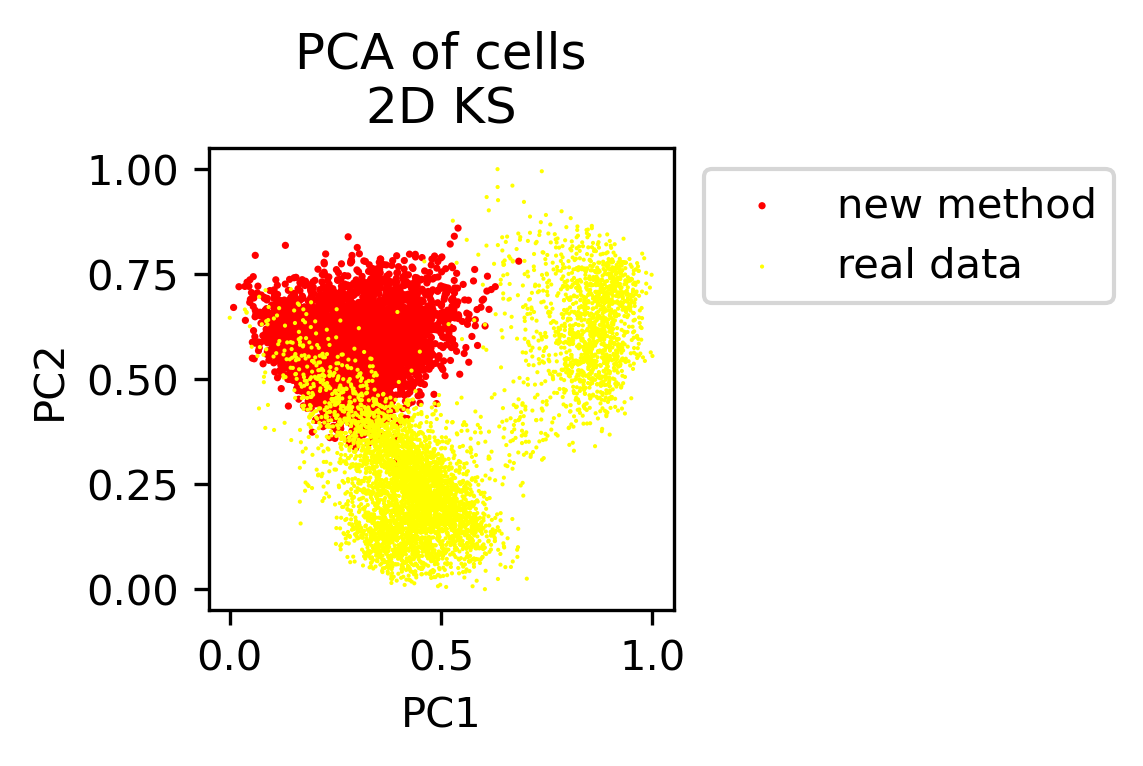

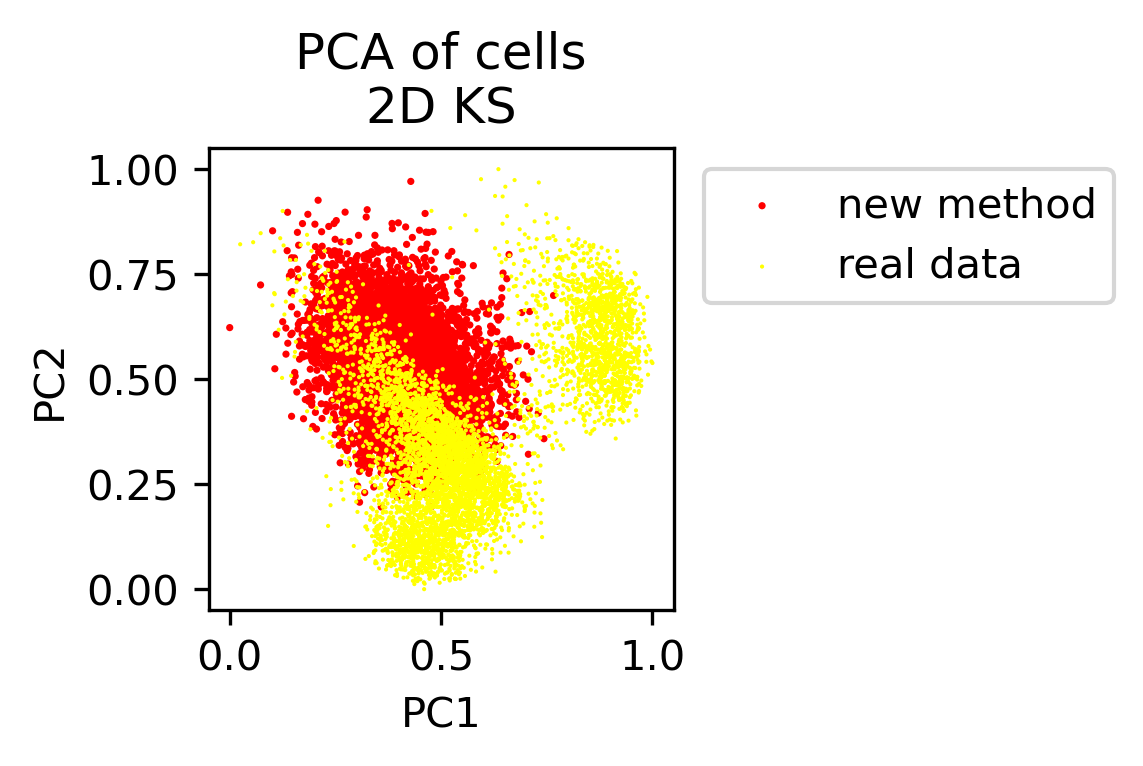

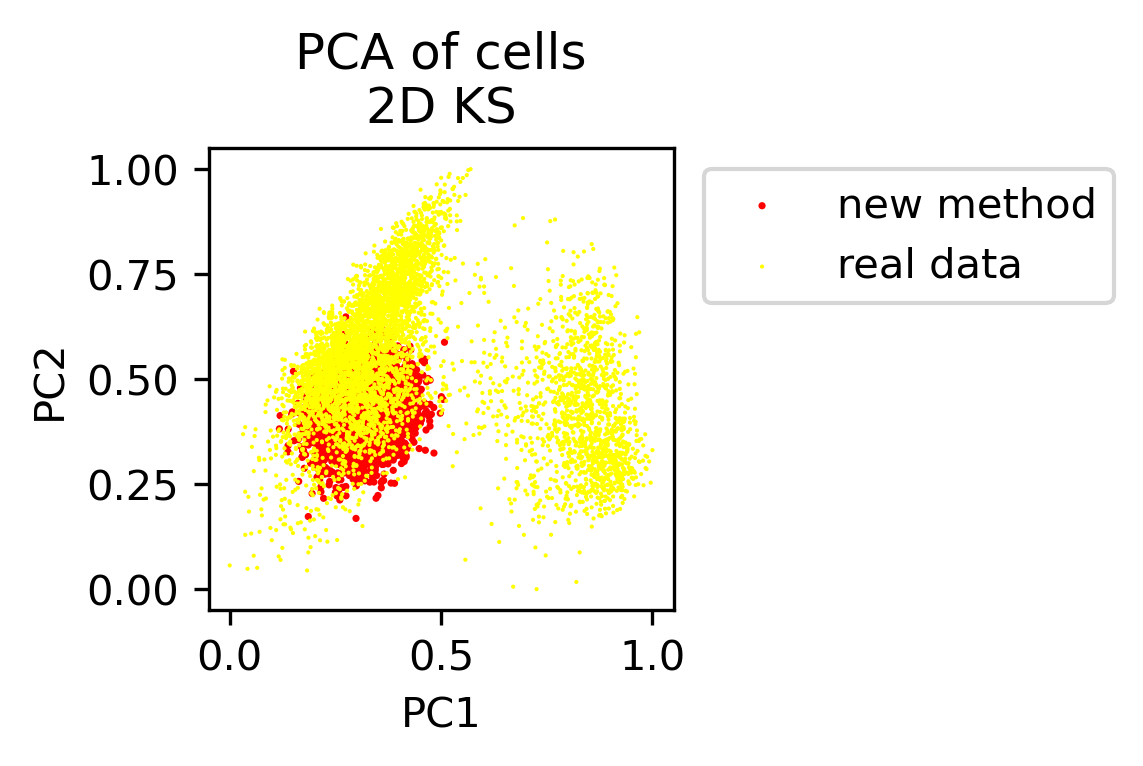

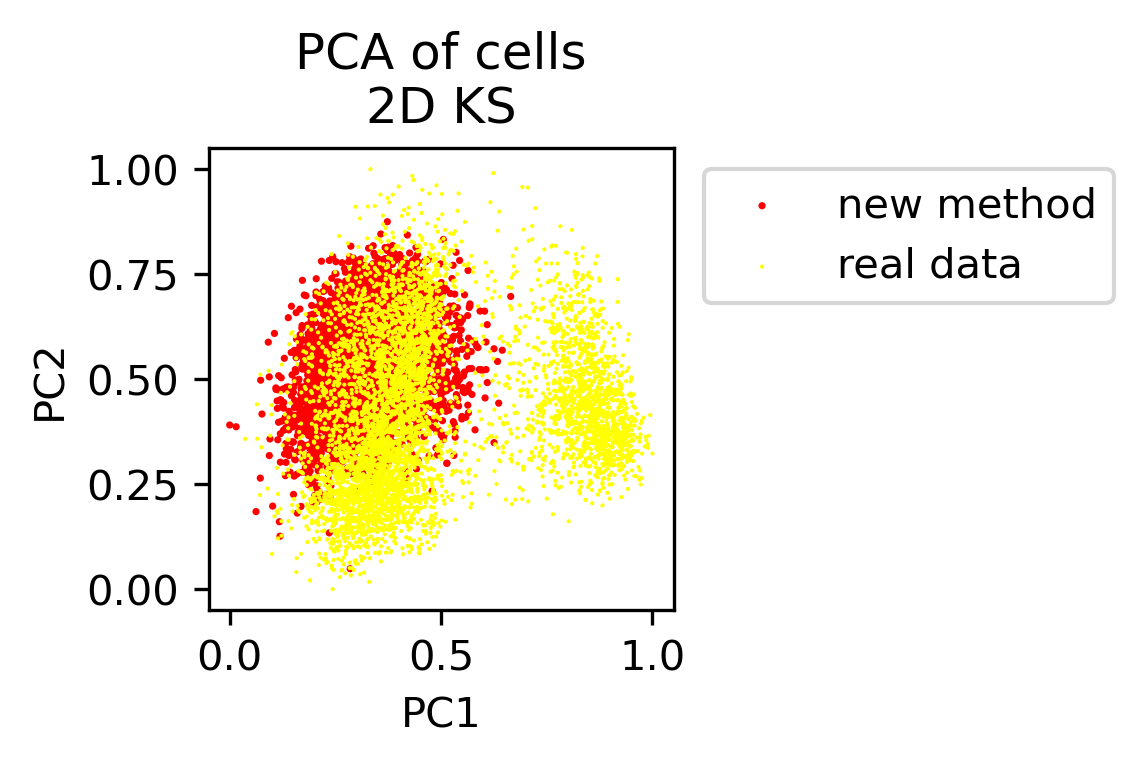

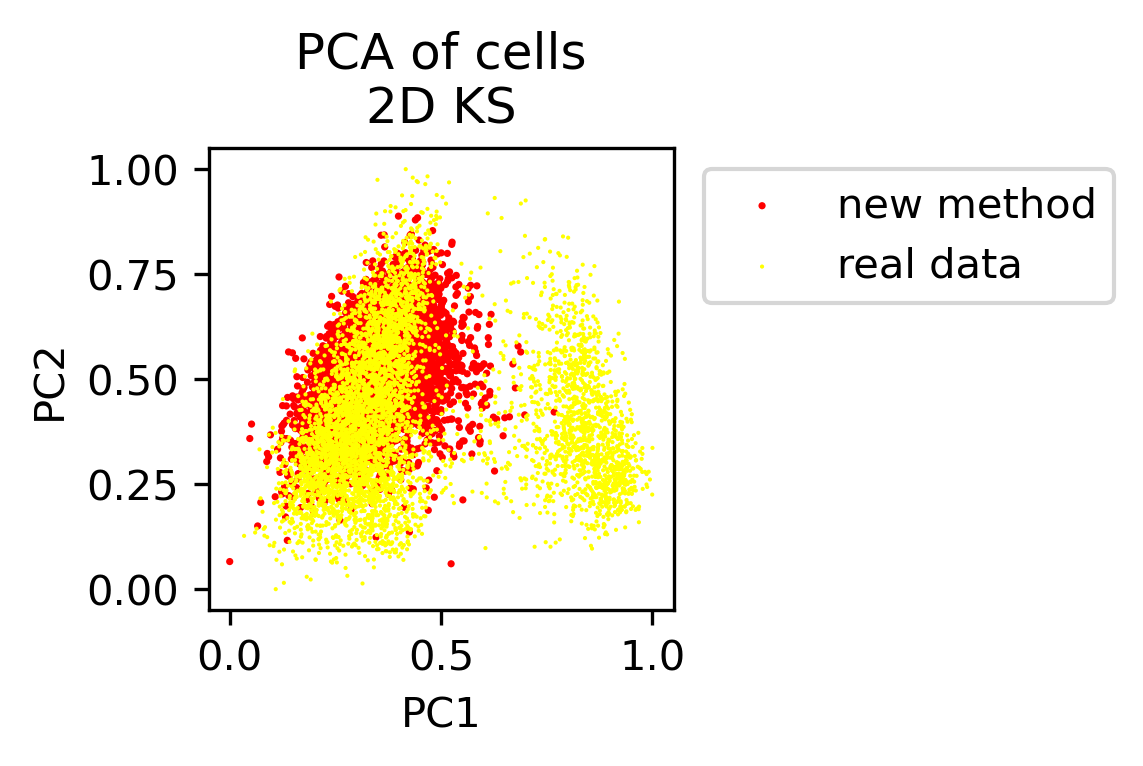

In [6]:

for i in [1,10,25,50,70]:
    real_adata = sc.read_h5ad(f"../../input/test_data_day_19.h5ad")
    # real_adata = real_data_origin[real_data_origin.obs['Group']==3]
    # real_data = sc.read_h5ad("../../input/plant_test_day0_data.h5ad")
    print("real_data:",real_adata)

    predict_data = sc.read_h5ad(f"../experiments/mice_exp6_infer_day_except_19_by_7_18_{i}_percent/interception_predict_to_day_19.h5ad")
    print("predict_data:",predict_data)
    # get_pairwase_2d(predict_data, real_adata,i)
    get_pca_2d(predict_data, real_adata,i)
    
